# The Ramanujan π Lab

A runnable companion to the ilm.red post **"Ramanujan and the series for 1/π: six papers, explained."**

In 1914 Srinivasa Ramanujan published 17 infinite sums for the number 1/π. In this notebook you will
run them yourself and *see* why mathematicians were astonished:

1. **A slow sum first**: the Leibniz series, which needs hundreds of terms for two digits.
2. **Ramanujan's fastest series**: about 8 new correct digits with every single term.
3. **The Chudnovsky formula** (1988): about 14 digits a term, the engine behind modern π records.
4. **A race**: all three on one chart.
5. **Evidence is not proof**: what a computer check can and cannot tell you.
6. **A conjugate pair**: flip the sign of a square root and watch what happens to a sum.

Standard library only (plus matplotlib for two charts). No accounts, no keys, no network.

In [1]:
from decimal import Decimal, getcontext
from math import factorial
import matplotlib.pyplot as plt

getcontext().prec = 320          # work with 320 significant digits

# 300 digits of pi, computed with Machin's 1706 formula, which is independent of every series below:
# pi = 16*arctan(1/5) - 4*arctan(1/239)
def arctan_inv(n):
    x = Decimal(1) / n
    total, term, k, n2 = x, x, 1, n * n
    while abs(term) > Decimal(10) ** -(getcontext().prec + 5):
        term = -term / n2
        total += term / (2 * k + 1)
        k += 1
    return total

PI = 16 * arctan_inv(5) - 4 * arctan_inv(239)
print(str(PI)[:62], "...")

def correct_digits(estimate):
    # How many digits after the decimal point agree with pi
    diff = abs(estimate - PI)
    if diff == 0:
        return getcontext().prec
    return max(0, -diff.adjusted() - 1)

Matplotlib is building the font cache; this may take a moment.


3.141592653589793238462643383279502884197169399375105820974944 ...


## 1. A slow sum first

The Leibniz series is the simplest sum for π:

$$\frac{\pi}{4} = 1 - \frac13 + \frac15 - \frac17 + \cdots$$

It is true, and it is painfully slow. Watch how many terms it takes to earn each digit.

In [2]:
def leibniz(terms):
    total = Decimal(0)
    for k in range(terms):
        total += Decimal((-1) ** k) / (2 * k + 1)
    return 4 * total

for n in (1, 10, 100, 1000, 10000):
    est = leibniz(n)
    print(f"{n:>6} terms -> {str(est)[:12]}   correct digits: {correct_digits(est)}")

     1 terms -> 4   correct digits: 0
    10 terms -> 3.0418396189   correct digits: 1
   100 terms -> 3.1315929035   correct digits: 2
  1000 terms -> 3.1405926538   correct digits: 3
 10000 terms -> 3.1414926535   correct digits: 4


Ten thousand terms, and only three digits after the decimal point are right. At this rate a million digits would
take longer than the age of the universe.

## 2. Ramanujan's fastest series (1914)

$$\frac{1}{\pi} = \frac{2\sqrt2}{9801}\sum_{k=0}^{\infty}\frac{(4k)!\,(1103+26390k)}{(k!)^4\,396^{4k}}$$

Every piece is ordinary arithmetic: factorials, powers, one square root. Count the digits after each term.

In [3]:
def ramanujan(terms):
    total = Decimal(0)
    for k in range(terms):
        num = Decimal(factorial(4 * k)) * (1103 + 26390 * k)
        den = Decimal(factorial(k)) ** 4 * Decimal(396) ** (4 * k)
        total += num / den
    one_over_pi = Decimal(2) * Decimal(2).sqrt() / 9801 * total
    return 1 / one_over_pi

ram_digits = []
for n in range(1, 9):
    est = ramanujan(n)
    d = correct_digits(est)
    ram_digits.append(d)
    print(f"{n} term(s) -> {str(est)[:40]}...   correct digits: {d}")

1 term(s) -> 3.14159273001330566031399618902521551859...   correct digits: 7
2 term(s) -> 3.14159265358979387799890582630601309421...   correct digits: 15
3 term(s) -> 3.14159265358979323846264906570275889815...   correct digits: 23
4 term(s) -> 3.14159265358979323846264338327955527315...   correct digits: 31
5 term(s) -> 3.14159265358979323846264338327950288419...   correct digits: 39
6 term(s) -> 3.14159265358979323846264338327950288419...   correct digits: 47
7 term(s) -> 3.14159265358979323846264338327950288419...   correct digits: 55
8 term(s) -> 3.14159265358979323846264338327950288419...   correct digits: 63


**One term** already gives 3.141592**7**: six digits from a single line of arithmetic.
After that, every new term adds about **8** more.

## 3. The Chudnovsky formula (1988)

$$\frac{1}{\pi} = 12\sum_{k=0}^{\infty}\frac{(-1)^k\,(6k)!\,(13591409+545140134k)}{(3k)!\,(k!)^3\,640320^{3k+3/2}}$$

David and Gregory Chudnovsky built this on the same idea as Ramanujan's series. It is the formula behind
most record computations of π.

In [4]:
def chudnovsky(terms):
    total = Decimal(0)
    for k in range(terms):
        num = Decimal((-1) ** k) * Decimal(factorial(6 * k)) * (13591409 + 545140134 * k)
        den = Decimal(factorial(3 * k)) * Decimal(factorial(k)) ** 3 * Decimal(640320) ** (3 * k)
        total += num / den
    one_over_pi = 12 * total / (Decimal(640320) ** 3).sqrt()
    return 1 / one_over_pi

chud_digits = []
for n in range(1, 9):
    est = chudnovsky(n)
    d = correct_digits(est)
    chud_digits.append(d)
    print(f"{n} term(s) -> correct digits: {d}")

1 term(s) -> correct digits: 13
2 term(s) -> correct digits: 27
3 term(s) -> correct digits: 41
4 term(s) -> correct digits: 55
5 term(s) -> correct digits: 70
6 term(s) -> correct digits: 84
7 term(s) -> correct digits: 98
8 term(s) -> correct digits: 112


## 4. The race

Digits earned against terms used. A straight line on this chart means "the same number of new digits with every
term". The steeper the line, the faster the series.

Ramanujan : about 8.0 new digits per term
Chudnovsky: about 14.1 new digits per term


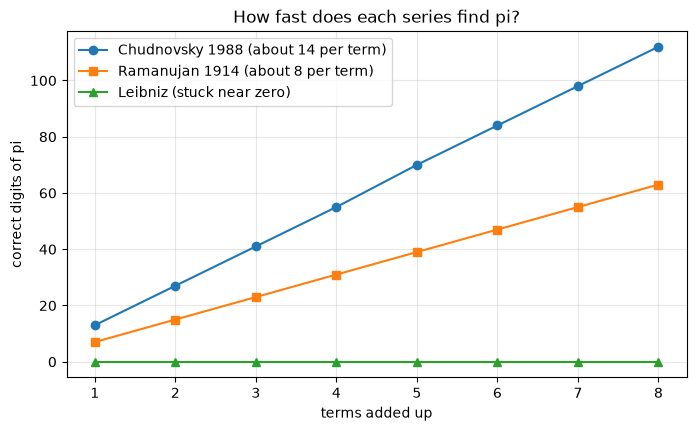

In [5]:
terms = list(range(1, 9))
gain_r = (ram_digits[-1] - ram_digits[0]) / (len(terms) - 1)
gain_c = (chud_digits[-1] - chud_digits[0]) / (len(terms) - 1)
print(f"Ramanujan : about {gain_r:.1f} new digits per term")
print(f"Chudnovsky: about {gain_c:.1f} new digits per term")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(terms, chud_digits, "o-", label=f"Chudnovsky 1988 (about {gain_c:.0f} per term)")
ax.plot(terms, ram_digits, "s-", label=f"Ramanujan 1914 (about {gain_r:.0f} per term)")
ax.plot(terms, [correct_digits(leibniz(n)) for n in terms], "^-", label="Leibniz (stuck near zero)")
ax.set_xlabel("terms added up")
ax.set_ylabel("correct digits of pi")
ax.set_title("How fast does each series find pi?")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 5. Evidence is not proof

We just checked Ramanujan's series against 300 digits of π. Is that a proof that the formula is *exactly* right?

No. Here is a famous warning. The number $e^{\pi\sqrt{163}}$ looks like a whole number for twelve decimal places
and then turns out not to be one. A check that stopped early would have "confirmed" something false.

In [6]:
def exp_dec(x):
    # e^x by its own series
    total, term, k = Decimal(1), Decimal(1), 1
    while abs(term) > Decimal(10) ** -(getcontext().prec):
        term = term * x / k
        total += term
        k += 1
    return total

value = exp_dec(PI * Decimal(163).sqrt())
print("e^(pi*sqrt(163)) =", str(value)[:40])
print("                   262537412640768743.99999999999925...  so close to a whole number, and not one.")
print()
print("Look at the number 640320 in the Chudnovsky formula. 640320^3 + 744 =", 640320 ** 3 + 744)

e^(pi*sqrt(163)) = 262537412640768743.999999999999250072597
                   262537412640768743.99999999999925...  so close to a whole number, and not one.

Look at the number 640320 in the Chudnovsky formula. 640320^3 + 744 = 262537412640768744


That last line is not a coincidence. The same deep structure (modular functions) explains both the near-integer and
the Chudnovsky formula, and **that structure is what a proof uses**. Matching digits can only ever say "true so far".
The six papers in the post are about turning "true so far" into "true, always".

## 6. A conjugate pair

The newest paper studies series that contain numbers like $a + b\sqrt{61}$, and asks what happens when you flip
the sign to $a - b\sqrt{61}$ (the *conjugate*). Sometimes the flipped series still adds up to something. Sometimes
it grows without end.

A toy model shows why a sign flip can matter so much. Take the simple sum $\sum x^k$:
it settles down only when $|x| < 1$.

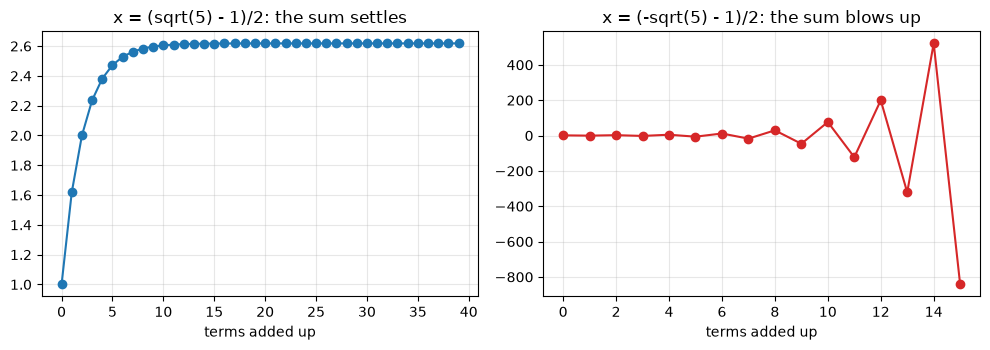

settles near 2.618034 = 1/(1 - x) = 2.618034


In [7]:
from math import sqrt

def partial_sums(x, n=40):
    total, out = 0.0, []
    for k in range(n):
        total += x ** k
        out.append(total)
    return out

x_plus = (sqrt(5) - 1) / 2        # about  0.618: smaller than 1 in size
x_minus = (-sqrt(5) - 1) / 2      # about -1.618: its conjugate, bigger than 1 in size

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(partial_sums(x_plus), "o-")
axes[0].set_title("x = (sqrt(5) - 1)/2: the sum settles")
axes[1].plot(partial_sums(x_minus, 16), "o-", color="tab:red")
axes[1].set_title("x = (-sqrt(5) - 1)/2: the sum blows up")
for a in axes:
    a.set_xlabel("terms added up"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("settles near", round(partial_sums(x_plus, 200)[-1], 6), "= 1/(1 - x) =", round(1 / (1 - x_plus), 6))

Same recipe, same two numbers under the square root, opposite sign: one sum converges and the other diverges.
The real series in the paper are far richer than this toy, but the question is the same one, and the paper's
classification explains which conjugates work.

## Try it yourself

- Change `getcontext().prec` to 1200 (and compute more digits of `PI`) and push Chudnovsky to 80 terms. Do you
  still get about 14 digits per term?
- Replace 26390 with 26391 in `ramanujan`. How many digits survive? This is what "the formula is exact" is protecting.
- Time the Leibniz series for 100,000 terms and compare it with one term of Ramanujan.